# Step 6 – Probabilistic forecasting models


| Module | Role |
|---|---|
| `src/models.py` | every model, the conformal layer, the combination, the Step 8 export, the hold-out evaluation and the leakage checks |
| `src/model_plots.py` | charts (saved in `plots/step6/`) |
| `tests/test_models.py` | leakage tests on every origin + power tests (deliberately leaky code must fail) |

**Reproduce** (from the repo root, after Steps 1, 4 and 5):

```bash
uv run --extra chronos python -m src.models            # base models, conformal, combination, Step 8 export (~3.5 min)
uv run python -m src.models --stage holdout            # the single hold-out evaluation (frozen, see section 7)
uv run --extra chronos pytest tests/                   # leakage tests (~10 min)
```

This notebook **reads the saved predictions** (`Data/processed/models/`) instead of refitting everything, so it runs in about two minutes. Set `RERUN = True` to refit (needs the `chronos` extra).

**Discipline.** Every choice (EWMA λ, conformal γ, combination members) was made on the **backtest** (target months ≤ March 2025). The **hold-out** (April 2025 → September 2026) was opened **once**, after all choices were frozen (section 7).

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
# The pipeline uses paths relative to the repo root (Data/, configs/).
if Path.cwd().name == "analysis":
    os.chdir("..")
import numpy as np
import pandas as pd
from IPython.display import display

from src import models as M, model_plots as MP, feature_plots as FP
from src.baselines import load_selected
from src.feature_selection import load_tables
from src.features import load_config, load_inputs, info_set

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)
FP.set_style()

RERUN = False  # True: refit every model (needs `uv sync --extra chronos`), ~3.5 min
cfg = load_config()
inputs = load_inputs()
tables = load_tables(cfg)
selected = load_selected()
SELECT_END = pd.Timestamp(cfg["selection"]["select_end"])
GROUPS = M.SETTINGS["pooled_groups"]
GROUP_OF = {t: g for g, ts in GROUPS.items() for t in ts}

if RERUN:
    for name in M.MODELS:
        M.run_model(name, inputs, tables, selected, cfg).to_csv(M.MODEL_DIR / f"predictions_{name}.csv", index=False)
    M.run_post(cfg)

preds = M.load_predictions()                       # every saved model + the Step 5 random walk
bt = M._backtest_metrics(preds, cfg)               # backtest rows only (refuses hold-out rows)
bt["grp"] = bt["target"].map(GROUP_OF)
print(f"{preds['model'].nunique()} models, {len(preds):,} forecasts; "
      f"backtest: target months <= {SELECT_END:%Y-%m}")

25 models, 54,590 forecasts; backtest: target months <= 2025-03


## 6.1 What every model forecasts, and how it is tested

Same target and timing as Steps 4 and 5: for each of the 15 materials, origin month *T* and horizon *H* ∈ {3, 6, 9},

```
y = log(P[T+H]) − log(P[T])        forecast as P10 / P50 / P90 (+ P95 for the pricing buffer)
```

- The forecast is made at the start of month *T* + 2 and only uses data **published by then** (Step 4 timing rule).
- **Rolling origin, expanding window:** at test origin *T* a model trains only on origins whose outcome was known (*o* + *H* ≤ *T*).
- **Same origins as Step 5:** 38 backtest origins (Nov 2021 →), 18 hold-out origins, plus the live September 2026 row.
- **Metrics** (Step 5): pinball loss averaged over P10/P50/P90, skill vs the random walk (`1 − loss / loss_RW`), coverage of the P10–P90 band (target 80 %), band width.

### Leakage proof, built into the design

A model never sees the data. It receives a `Context` that holds **only what was known at the origin**: the target's known history, the known panel (`info_set`), the training rows with *o* + *H* ≤ *T*, and the features at *T*. On top, `poisoned_future_check` replaces **everything not yet known** with random numbers, inside the shared data itself (so even a model reading a global variable is caught), and checks that no forecast changes. The full version (every origin, every model, every conformal γ) runs in `tests/test_models.py`; here is a quick version on 3 origins.

In [2]:
quick = pd.concat([M.poisoned_future_check(m, inputs, tables, selected, cfg, n=3)
                   for m in ["ewma_fhs", "features_scaled", "pooled_qr"]], ignore_index=True)
display(quick.groupby("model")["unchanged"].agg(forecasts_checked="count", unchanged="sum"))

# Power check: a model that reads the future through a global must FAIL the same test.
@M.register("_leaky_demo", approach="direct")
def _leaky(ctx, p):
    return np.repeat(tables[(ctx.target, ctx.h)]["y"].iloc[-2], 4)   # reads a future outcome
leaky = M.poisoned_future_check("_leaky_demo", inputs, tables, selected, cfg, n=3, targets=["S09"], horizons=[3])
M.MODELS.pop("_leaky_demo")
print("deliberately leaky model caught:", not leaky["unchanged"].any())

,forecasts_checked,unchanged
model,,
ewma_fhs,135,135
features_scaled,135,135
pooled_qr,135,135


deliberately leaky model caught: True


Results of the full test suite (`uv run --extra chronos pytest tests/`): every model passes on **all 57 origins** (2,565 forecasts each), the conformal layer passes on all 57 origins × 4 values of γ (286,896 comparisons), and three deliberately leaky versions (future feature rows, unpublished panel data, an off-by-one on the arrival date) are all caught.

## 6.2 Volatility-scaled random walk (`ewma_fhs`) and the √H trap

The Step 5 random walk has the right median (no model beats "no change" for market prices) but its band is fixed: too narrow in 2022, too wide in 2025. `ewma_fhs` keeps the median at 0 and rescales the band by today's volatility.

**The trap.** The textbook way, `σ_monthly × √H`, assumes months are independent. The chart shows the ratio *variance of 9-month changes / (9 × variance of monthly changes)*: 1 means independent months.

,min,median,max
group,,,
epoxy,2.410,2.410,2.410
market,0.846,1.222,1.696
ppi,1.294,4.975,5.772


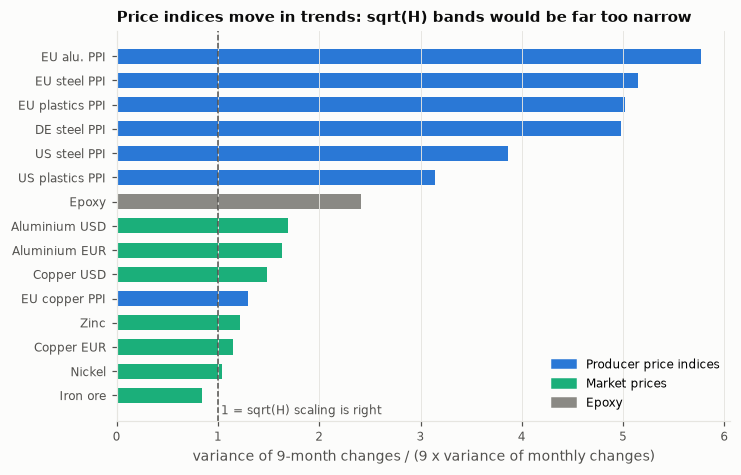

In [3]:
rows = []
for t, g in GROUP_OF.items():
    lp = np.log(inputs.data[t].loc[:SELECT_END].dropna())
    r = lp.diff()
    rows.append({"target": t, "group": g, "ratio": (lp.shift(-9) - lp).var() / (9 * r.var())})
vr = pd.DataFrame(rows)
MP.variance_ratio(vr);
display(vr.groupby("group")["ratio"].agg(["min", "median", "max"]))

The producer price indices move in trends (Step 3: lag-1 autocorrelation 0.5–0.8), so their 9-month variance is several times what √H assumes. **`ewma_fhs` therefore works on H-month changes directly** (filtered historical simulation):

```
z_o = y_o / s_o          s_o = RMS of the monthly returns inside (o, o+H]   (known, since o + H ≤ T)
q_k = σ_T × (quantile_k(z) − median(z))      σ_T = EWMA volatility at the origin
```

The momentum stays inside *z*; only the volatility level is updated.

**A rejected first version.** Dividing by the volatility *at the origin* instead of *during the window* failed: the 2021 surge started from calm months, so it became an extreme *z*, then multiplied by the high 2022 volatility. 9-month price-index bands came out twice as wide as the random walk's (98 % coverage, skill −23 %).

**λ:** compared on the backtest only.

In [4]:
lam = []
for l in M.SETTINGS["ewma_lambdas_to_compare"]:
    p = M.run_model("ewma_fhs", inputs, tables, selected, cfg, params={"ewma_lambda": l}).assign(model=f"lambda_{l}")
    m = M._backtest_metrics(pd.concat([preds[preds.model == "random_walk"], p]), cfg)
    m = m[m.model != "random_walk"]
    lam.append({"lambda": l, "skill_vs_rw": m.pinball_skill_vs_rw.mean(), "coverage_80": m.coverage_80.mean()})
display(pd.DataFrame(lam))

,lambda,skill_vs_rw,coverage_80
0,0.94,0.048,0.886
1,0.97,0.057,0.870


λ = 0.97 (half-life ≈ 23 months) is slightly ahead and is the plan's standard value; the difference is within noise.

## 6.3 Adaptive conformal calibration (a layer on every model)

Each tail is rescaled around the median by its own factor, learnt online from outcomes already known at the origin: a miss widens that tail by about γ, a hit narrows it by γ × target, so each tail is missed at its target rate (10 % for P10 and P90, 5 % for P95), even when the regime changes. P50 never moves. γ is chosen per model on the backtest (γ = 0 means "off").

In [5]:
g = pd.read_csv(M.TABLE_DIR / "conformal_gamma.csv")
display(g[g.chosen][["model", "gamma", "pinball", "coverage_80", "coverage_p90", "coverage_p95"]].sort_values("pinball"))
live = pd.read_csv(M.MODEL_DIR / "predictions_conformal_ewma_fhs.csv", parse_dates=["origin"])
live = live[live.origin == live.origin.max()]
print("scale factors learnt by Sep 2026 (median over the 45 cells):",
      live[["scale_p10", "scale_p90", "scale_p95"]].median().round(2).to_dict())

,model,gamma,pinball,coverage_80,coverage_p90,coverage_p95
25,features_scaled,0.00,2.457,0.879,0.956,0.968
46,combo,0.02,2.780,0.870,0.952,0.957
38,gjr_fhs,0.10,2.805,0.832,0.943,0.950
33,garch_fhs,0.10,2.817,0.859,0.945,0.952
23,ewma_fhs,0.10,2.839,0.866,0.946,0.952
43,pooled_qr,0.10,3.017,0.901,0.958,0.964
10,auto_theta,0.00,3.032,0.717,0.941,0.958
5,auto_ets,0.00,3.112,0.782,0.937,0.972
15,chronos_bolt,0.00,3.131,0.868,0.960,0.980
0,auto_arima,0.00,3.215,0.849,0.955,0.980


scale factors learnt by Sep 2026 (median over the 45 cells): {'scale_p10': 0.79, 'scale_p90': 0.97, 'scale_p95': 1.13}


The layer helps little (about −0.5 % loss for `ewma_fhs`) because each cell has only 18–38 outcomes and the volatility scaling had already fixed most of the band. It is kept as a cheap safety net. By September 2026 it has learnt that the **downside** band was too wide (P10 factor ≈ 0.8) and the **extreme upside** slightly too narrow (P95 factor ≈ 1.1): risk is skewed up, as Step 3 found.

## 6.4 GARCH and GJR-GARCH (`garch_fhs`, `gjr_fhs`)

Same as `ewma_fhs`, but the volatility of the coming *H* months comes from a GARCH(1,1) with Student-t errors, which **reverts to its long-run level** over the horizon (EWMA stays flat). GJR lets price rises raise volatility more than falls. When the fit fails or is not stationary, the model falls back to EWMA and records why (the plan asks for the fallback rate).

In [6]:
fb = []
for m in ["garch_fhs", "gjr_fhs"]:
    p = preds[(preds.model == m) & (preds.horizon == 3)]
    fb.append(p.assign(fallback=p.note.fillna("").str.startswith("ewma")).groupby("target").fallback.mean().rename(m))
fb = pd.concat(fb, axis=1).rename(index=FP.TARGET_NAMES).sort_values("garch_fhs", ascending=False)
display(fb.style.format("{:.0%}"))

,garch_fhs,gjr_fhs
target,,
EU plastics PPI,100%,61%
EU steel PPI,96%,72%
US steel PPI,95%,40%
DE steel PPI,93%,14%
Copper USD,32%,32%
Copper EUR,26%,21%
EU copper PPI,26%,21%
EU alu. PPI,21%,0%
Epoxy,14%,0%


GARCH works for market prices but **falls back to EWMA almost always for the steel and plastics PPIs**: their fitted volatility is so persistent that it never settles to a long-run level (integrated GARCH). Most likely the PPIs' smooth trends look like one long volatility episode to a zero-mean GARCH. In practice GARCH ≈ EWMA for those series; ARMA-GARCH would be the fix.

## 6.5 Step 4 features as the median (`features_scaled`)

Median from the Step 4 selected features (median quantile regression, same fit as Steps 4–5), band from the **residuals** of that median, volatility-scaled. It runs on **all 17 cells where Step 4 kept features**, not only S08/S09/S10: those three were singled out by the Step 5 *hold-out*, and choosing cells there would contaminate it.

In [7]:
cells = bt[bt.model == "features_scaled"][["target", "horizon"]]
f = bt.merge(cells, on=["target", "horizon"])
f = f[f.model.isin(["features_qr", "ewma_fhs", "features_scaled"])]
tab = f.pivot_table(index=["target", "horizon"], columns="model", values=["pinball_skill_vs_rw", "coverage_80"])
display(tab.round(3))
display(f.groupby("model")[["pinball_skill_vs_rw", "coverage_80"]].mean())

coverage_80                             pinball_skill_vs_rw                            
model                ewma_fhs features_qr features_scaled            ewma_fhs features_qr features_scaled
target    horizon                                                                                        
D01       3             0.816       0.842           0.816               0.005       0.012          -0.017
D02       9             0.906       0.750           0.906               0.039       0.068           0.024
EPOXY_EUR 6             0.952       0.810           0.810               0.103      -0.050          -0.046
S03       3             0.763       0.763           0.816              -0.058       0.038           0.007
S04       6             0.971       0.886           0.857              -0.017       0.003          -0.042
S05       6             0.857       0.886           0.829              -0.033      -0.072          -0.217
S08       3             0.632       0.605           0.895               0.001       0.274           0.252
          6             0.857       0.457           0.829               0.148       0.102          -0.027
          9             1.000       0.625           0.938               0.251       0.061           0.122
S09       3             0.684       0.684           0.868              -0.006       0.184           0.221
S10       3             0.711       0.658           0.842               0.023       0.203           0.178
S11       3             0.842       0.684           0.895              -0.123       0.164           0.224
          6             0.886       0.686           0.886               0.078       0.058           0.110
          9             1.000       0.625           0.969               0.228      -0.058           0.157
S12       3             0.947       0.789           1.000               0.229       0.129           0.247
S13       6             0.800       0.829           0.914               0.134       0.090           0.184
          9             0.875       0.906           0.875               0.245       0.095           0.228

,pinball_skill_vs_rw,coverage_80
model,,
ewma_fhs,0.073,0.853
features_qr,0.077,0.734
features_scaled,0.094,0.879


On its cells, `features_scaled` keeps the skill of `features_qr` and **fixes its calibration** (coverage 73 % → 88 %). The gain is concentrated in the PPIs at 3 months (S08, S09, S10, S11, S12: +18 to +25 %). Its backtest scores are optimistic: the features were chosen on this same window in Step 4.

## 6.6 Pooled ("global") quantile regression (`pooled_qr`)

One quantile regression on all 15 materials stacked (about 800–1,300 rows instead of about 90), on volatility-standardised changes, with momentum features and a price-index indicator. Coefficients of the 3-month model fitted at March 2025:

In [8]:
from src.feature_selection import _fit
T = SELECT_END
X, z = M.pooled_training_data(info_set(inputs, T, 2), T, 3, M.SETTINGS["ewma_lambda"], GROUPS)
fit = _fit(X, z, [0.1, 0.5, 0.9], M.SETTINGS["pooled_alpha_rel"])
display(pd.DataFrame({q: mod.coef_ for q, mod in zip(["P10", "P50", "P90"], fit["models"])},
                     index=M.POOLED_FEATURES).round(3))
print("training rows:", len(z))

,P10,P50,P90
mom_1m,0.000,0.111,0.000
mom_3m,0.000,0.000,0.000
is_ppi,-0.033,-0.247,0.000
is_epoxy,0.000,0.000,0.000
mom_1m_x_ppi,0.037,0.386,0.045
mom_3m_x_ppi,0.000,0.431,0.039


training rows: 1276


Momentum only enters through the **price-index interactions** (`mom_1m_x_ppi`, `mom_3m_x_ppi`): an independent confirmation of Step 4 (momentum in PPIs, none in LME prices). Overall the pooled model does **not** beat `ewma_fhs` (backtest skill −0.1 %; three variants tried, none better): for market prices the best median is "no change", and a shared band shape is too wide for them. It is reported as tested, not used.

## 6.7 Classical models (`auto_ets`, `auto_arima`, `auto_theta`, statsforecast)

Fitted on log prices known at the origin, recursive multi-step forecasts, their own Gaussian prediction intervals. What they choose at March 2025:

In [9]:
from statsforecast.models import AutoARIMA, AutoETS
kn = info_set(inputs, SELECT_END, 2)
rows = []
for t in GROUP_OF:
    y = np.log(kn[t].loc[:SELECT_END].dropna().to_numpy())
    a = AutoARIMA(max_p=2, max_q=2, seasonal=False).fit(y)
    e = AutoETS(model="ZZN", season_length=1).fit(y)
    o = a.model_["arma"]
    rows.append({"target": FP.TARGET_NAMES[t], "group": GROUP_OF[t], "ARIMA (p,d,q)": (o[0], o[5], o[1]), "ETS": e.model_["method"]})
display(pd.DataFrame(rows))

,target,group,"ARIMA (p,d,q)",ETS
0,Copper USD,market,"(2, 1, 2)","ETS(M,N,N)"
1,Copper EUR,market,"(2, 1, 2)","ETS(M,N,N)"
2,Aluminium USD,market,"(0, 1, 1)","ETS(M,N,N)"
3,Aluminium EUR,market,"(0, 1, 1)","ETS(M,N,N)"
4,Nickel,market,"(1, 1, 0)","ETS(M,N,N)"
5,Iron ore,market,"(0, 1, 1)","ETS(M,N,N)"
6,Zinc,market,"(2, 0, 1)","ETS(M,N,N)"
7,EU copper PPI,ppi,"(2, 1, 2)","ETS(M,N,N)"
8,EU alu. PPI,ppi,"(1, 1, 1)","ETS(M,Ad,N)"
9,EU steel PPI,ppi,"(1, 1, 0)","ETS(M,Ad,N)"


ETS picks **no trend** for every market price (a smoothed random walk) and a **damped trend** for 6 of 7 PPIs; ARIMA picks AR terms for the PPIs. Both detect the PPI momentum, but they **extrapolate it too far**: helpful at 3 months, harmful at 6–9 months, when the 2022–24 trends reversed. Their Gaussian intervals are also too narrow for fat-tailed prices (Theta covers 72 %). Answer to the plan's question: there is autocorrelation to exploit beyond the random walk, but only for about one quarter.

## 6.8 Chronos-Bolt, zero-shot (`chronos_bolt`)

Amazon's pretrained time-series model (`chronos-bolt-small`, revision pinned, Apache-2.0), no training on our data: its context is the target's prices known at the origin; it returns P10/P50/P90 directly (P95 extrapolated, since Bolt is trained only up to P90). About 14 ms per forecast on a laptop CPU. The backtest years may be in its pretraining data, so it is **judged on the hold-out** (section 7).

## 6.9 All models on the backtest

,cells,skill,coverage,all_cells,coverage_ok
model,,,,,
features_scaled,17,0.094,0.879,False,True
conformal_combo,45,0.085,0.870,True,True
combo,45,0.085,0.871,True,True
gjr_fhs,45,0.066,0.815,True,True
garch_fhs,45,0.063,0.862,True,True
ewma_fhs,45,0.057,0.870,True,True
random_walk,45,0.000,0.760,True,True
pooled_qr,45,-0.001,0.905,True,False
auto_theta,45,-0.008,0.717,True,True


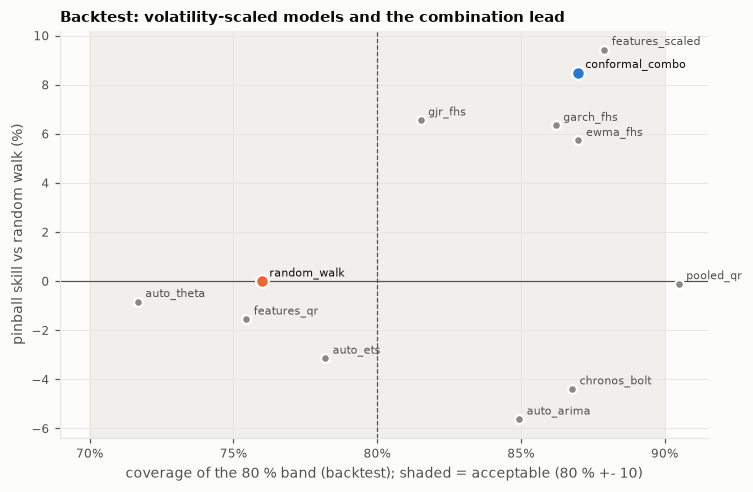

In [10]:
summ = M.model_summary(bt, cfg)
order = [m for m in summ.index if not m.startswith("conformal_") or m == "conformal_combo"]
display(summ.loc[order].round(3))
plot_models = [m for m in order if m not in ("lme_forward", "drift", "hist_quantiles", "combo")]
MP.skill_vs_coverage(summ.loc[plot_models], final=M.FINAL_MODEL);

## 6.10 Equal-weight combination

The plan's rule, applied on the backtest only (`build_combination`):

1. Only models that forecast **every** cell compete; first keep those with acceptable coverage (80 % ± 10), then the highest skill. Sizes 3 and 4 are tried and the better one kept.
2. A model that covers only some cells (`features_scaled`) joins in its cells if it beats the combination there (one yes/no decision, not per cell).
3. Equal-weight average of the quantiles, then the conformal layer.

In [11]:
display(pd.read_csv(M.TABLE_DIR / "combo_selection.csv"))
c = preds[preds.model == M.FINAL_MODEL]
print("members:", c["members"].iloc[0], "| members per forecast:", c.n_members.value_counts().to_dict())
display(bt[bt.model.isin(["random_walk", "gjr_fhs", M.FINAL_MODEL])]
        .pivot_table(index=["grp", "horizon"], columns="model", values=["pinball_skill_vs_rw", "coverage_80"]).round(3))

,step,candidate,backtest_skill,chosen,combo_skill_same_cells
0,size,"best 3: gjr_fhs, garch_fhs, ewma_fhs",0.069,False,NaN
1,size,"best 4: gjr_fhs, garch_fhs, ewma_fhs, auto_theta",0.072,True,NaN
2,specialist,features_scaled on its 17 cells,0.094,True,0.092


members: gjr_fhs, garch_fhs, ewma_fhs, auto_theta, features_scaled | members per forecast: {4.0: 1475, 5.0: 913}


coverage_80                     pinball_skill_vs_rw                    
model          conformal_combo gjr_fhs random_walk     conformal_combo gjr_fhs random_walk
grp    horizon                                                                            
epoxy  3                 0.917   0.875       0.917               0.036   0.057         0.0
       6                 0.857   0.857       0.905               0.063   0.125         0.0
       9                 1.000   1.000       1.000               0.107   0.133         0.0
market 3                 0.831   0.816       0.793               0.006  -0.003         0.0
       6                 0.886   0.906       0.865               0.015   0.022         0.0
       9                 0.884   0.857       0.830               0.029   0.026         0.0
ppi    3                 0.835   0.677       0.703               0.103   0.010         0.0
       6                 0.845   0.759       0.669               0.148   0.121         0.0
       9                 0.915   0.835       0.621               0.216   0.201         0.0

On the backtest the combination is the best model: **+8.5 % skill vs the random walk with 87 % coverage**, against +6.6 % for the best single model. Its biggest gain is price indices at 3 months (+10 % with 84 % coverage). Caveat: three of its four generalists are variants of the same volatility-scaled random walk, and every choice was made on this window, so this number is optimistic. The hold-out decides.

## 6.11 Diagnostics: residual checks and covariates

**Ljung–Box tests**  on the data known at the end of the backtest, per target, lag 12. A p-value below 0.05 means autocorrelation is left: in the residuals (structure in the median) or in the squared residuals (volatility clustering the model did not absorb). Low power on about 100 points: "not rejected" does not prove there is none.

In [12]:
rc = M.residual_checks(inputs, cfg)
rc["group"] = rc["target"].map(GROUP_OF)
left = rc.assign(residuals=rc.p_resid_lag12 < 0.05, squared=rc.p_squared_lag12 < 0.05)
display(left.groupby(["series", "group"])[["residuals", "squared"]].mean().unstack().style.format("{:.0%}"))

- **Raw returns** show both effects (PPI momentum, volatility clustering): what the models must handle.
- **GARCH** removes the volatility clustering wherever it can be fitted (0 % left). **EWMA** removes it for market prices but **not for 71 % of the PPIs**, the same series where GARCH falls back to EWMA (6.4). Their bands still reached the right coverage on the hold-out, but this is where a better volatility model (ARMA-GARCH) would help.
- **Linear autocorrelation stays** in the EWMA / GARCH residuals of the PPIs (momentum). That is expected and handled: the volatility models forecast H-month changes directly, so the momentum is inside the standardised H-month changes *z* (6.2), not assumed away.
- **ARIMA** absorbs most PPI momentum (14 % left) but leaves clustering; **ETS** leaves both, consistent with its weaker scores.

**Covariates used by `features_scaled`**, and whether the fitted effect on the median has the sign the Step 4 cause → effect chain predicts (`configs/features.yaml`). Coefficient per one standard deviation of the feature, fitted on the backtest window and at the live origin. The features **help predict**; this does not show that they cause the move.

In [13]:
cc = M.covariate_check(inputs, tables, selected, cfg)
display(cc[cc.fit == "live"][["target", "horizon", "feature", "group", "expected_sign", "coef_median_per_sd", "sign_agrees"]])
print("sign agrees, drivers:", cc[cc.group == "driver"].sign_agrees.mean(), "| own-price features:", round(cc[cc.group == "own"].sign_agrees.mean(), 2))

,target,horizon,feature,group,expected_sign,coef_median_per_sd,sign_agrees
1,D01,3,own_pos_12m_range,own,-,0.004,False
3,D02,9,own_chg_1m,own,+,0.016,True
6,S08,3,own_chg_1m,own,+,0.026,True
7,S08,3,d02_chg_1m,driver,+,0.016,True
9,S08,6,own_chg_1m,own,+,0.060,True
11,S08,9,d02_chg_1m,driver,+,0.032,True
14,S03,3,own_chg_3m,own,+,-0.075,False
15,S03,3,own_chg_1m,own,+,0.061,True
17,S04,6,own_chg_3m,own,+,-0.074,False
19,S05,6,own_chg_3m,own,+,0.018,True


sign agrees, drivers: 1.0 | own-price features: 0.71


**All 8 market drivers have the expected sign**, in both fits: LME aluminium → EU aluminium PPI, Brent → plastics and epoxy, iron ore → US steel PPI, WTI → US plastics. The 4 disagreements are **own-price** features, where Step 4 only enforced a sign for drivers:
- nickel and iron ore: a large 3-month rise partly **reverses** (Step 4, section 6.3), against the "+" momentum prior;
- copper's position in its 12-month range only affects the band (coefficient ≈ 0 on the median);
- US plastics' level above its 12-month average acts as a **trend**, not a reversal (the config allows either).

## 7. The single hold-out evaluation

`holdout_evaluation` first writes `holdout_freeze.json`: a SHA-256 fingerprint of every prediction file and decision table, and every setting. If anything changes afterwards, it refuses to run (tested). The call below **re-reads** the frozen evaluation; it reproduces the same numbers because nothing changed.

Confidence intervals: moving-block bootstrap over origins (blocks of *H* months; all targets of an origin move together). The hold-out has 18 origins per horizon, i.e. **6 / 3 / 2 independent windows** at 3 / 6 / 9 months.

,model,horizon,pinball_skill,pinball_skill_lo,pinball_skill_hi,mae_skill,coverage_80,coverage_p90,beats_naive_pinball,beats_naive_pinball_ci
0,conformal_combo,3,0.025,-0.009,0.053,0.016,0.837,0.856,True,False
1,conformal_combo,6,-0.005,-0.058,0.060,0.011,0.796,0.815,False,False
2,conformal_combo,9,0.008,-0.039,0.085,0.011,0.819,0.837,True,False
3,combo,3,0.021,-0.013,0.048,0.016,0.833,0.856,True,False
4,combo,6,-0.001,-0.041,0.047,0.011,0.819,0.837,False,False
5,combo,9,0.014,-0.022,0.070,0.011,0.830,0.844,True,False
6,gjr_fhs,3,-0.006,-0.043,0.023,0.000,0.774,0.837,False,False
7,gjr_fhs,6,-0.015,-0.054,0.040,0.000,0.796,0.841,False,False
8,gjr_fhs,9,0.007,-0.029,0.064,0.000,0.822,0.867,True,False
9,ewma_fhs,3,-0.005,-0.037,0.020,0.000,0.793,0.848,False,False


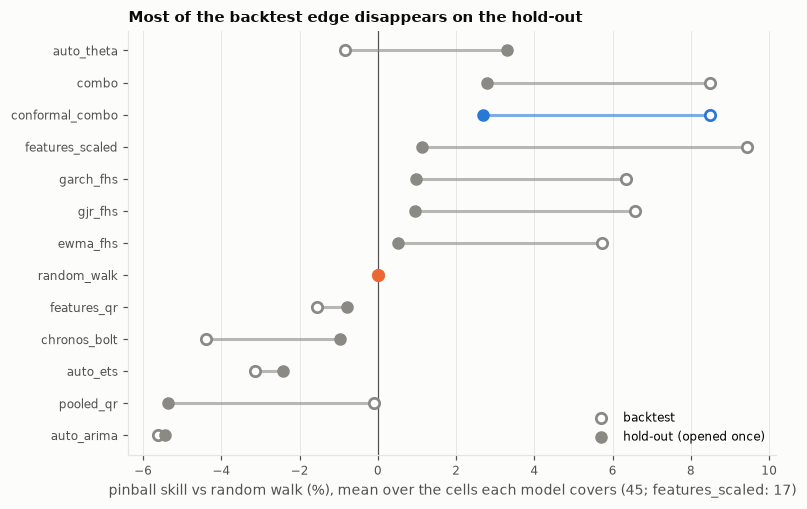

In [14]:
ho = M.holdout_evaluation(cfg)
b = ho["holdout_beats_naive"]
cols = ["model", "horizon", "pinball_skill", "pinball_skill_lo", "pinball_skill_hi", "mae_skill",
        "coverage_80", "coverage_p90", "beats_naive_pinball", "beats_naive_pinball_ci"]
display(b[cols].round(3))
MP.backtest_vs_holdout(ho["backtest_vs_holdout"].drop(index=[i for i in ho["backtest_vs_holdout"].index
                       if i.startswith("conformal_") and i != M.FINAL_MODEL or i in ("drift", "hist_quantiles", "lme_forward")]),
                       final=M.FINAL_MODEL);

coverage_80             pinball_skill_vs_rw                    width_80            
model          conformal_combo random_walk     conformal_combo random_walk conformal_combo random_walk
grp    horizon                                                                                        
epoxy  3                 0.833       0.833              -0.052         0.0          12.005      14.380
       6                 0.722       1.000               0.040         0.0          19.200      28.037
       9                 1.000       1.000               0.169         0.0          25.196      36.841
market 3                 0.825       0.817               0.010         0.0          27.545      28.788
       6                 0.825       0.865              -0.022         0.0          40.467      41.500
       9                 0.825       0.913              -0.035         0.0          50.606      52.797
ppi    3                 0.849       0.841               0.091         0.0          12.195      15.414
       6                 0.778       0.889               0.032         0.0          19.349      26.499
       9                 0.786       0.960               0.075         0.0          26.543      39.276

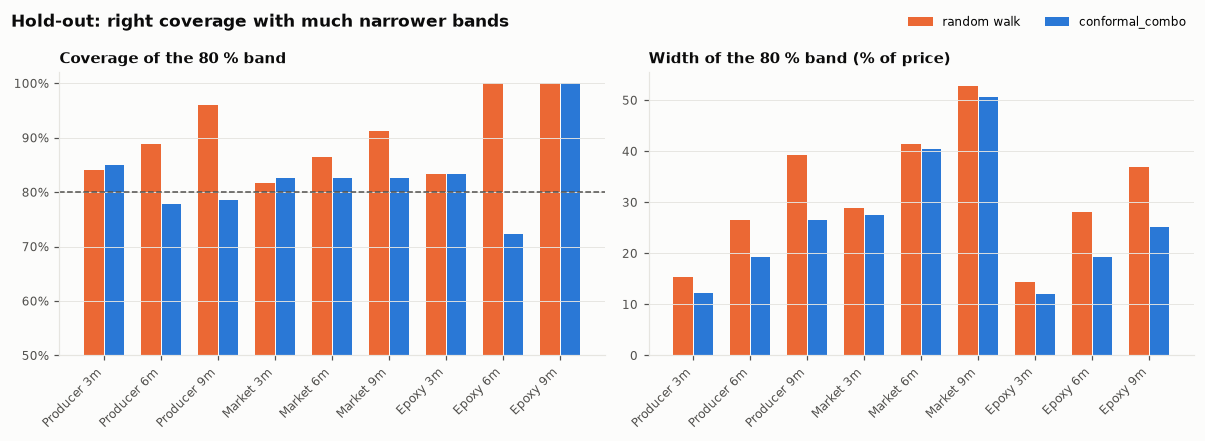

In [15]:
hm = ho["holdout_metrics"].copy()
hm["grp"] = hm["target"].map(GROUP_OF)
MP.holdout_coverage_width(hm, final=M.FINAL_MODEL);
display(hm[hm.model.isin(["random_walk", M.FINAL_MODEL])]
        .pivot_table(index=["grp", "horizon"], columns="model", values=["pinball_skill_vs_rw", "coverage_80", "width_80"]).round(3))

**The upside tail.** The final model's one-sided P90 covered 82–86 % on the hold-out instead of 90 %. Where:

horizon,3,6,9
target,,,
Copper EUR,28%,39%,50%
Copper USD,22%,33%,50%
EU copper PPI,33%,39%,50%
EU alu. PPI,17%,33%,33%
EU plastics PPI,17%,33%,28%
Aluminium EUR,17%,22%,11%
Aluminium USD,22%,22%,11%
US plastics PPI,17%,22%,11%
Epoxy,17%,28%,0%


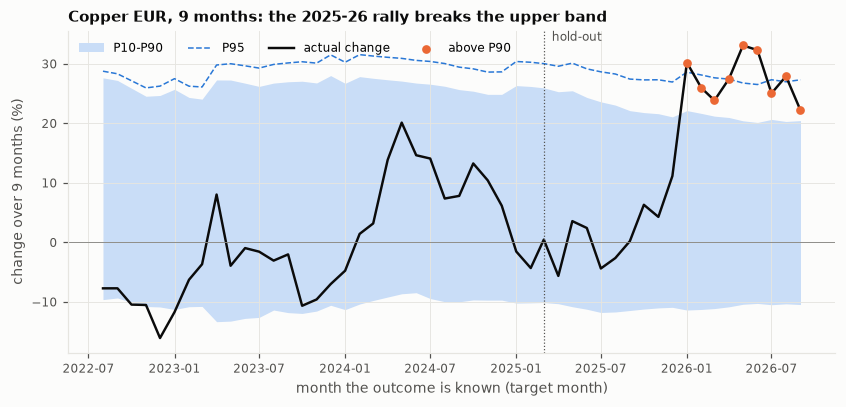

In [16]:
h = preds[(preds.model == M.FINAL_MODEL) & (preds.target_month > SELECT_END)].dropna(subset=["y"])
miss = h.assign(above_p90=h.y > h.p90).pivot_table(index="target", columns="horizon", values="above_p90")
display(miss.rename(index=FP.TARGET_NAMES).sort_values(9, ascending=False).style.format("{:.0%}"))
MP.upside_tail(preds[preds.model == M.FINAL_MODEL], "D01", 9, cfg["selection"]["select_end"]);

**Strict hold-out** (origins from March 2025 on, so that no part of an outcome window was visible when anything was chosen): too few independent windows (5 / 2 / 1) to conclude; shown for completeness.

In [17]:
s = ho["holdout_strict_beats_naive"]
display(s[s.model.isin([M.FINAL_MODEL, "random_walk", "chronos_bolt", "lme_forward"])]
        [["model", "horizon", "n_origins", "independent_windows", "pinball_skill", "coverage_80", "coverage_p90"]].round(3))

,model,horizon,n_origins,independent_windows,pinball_skill,coverage_80,coverage_p90
0,conformal_combo,3,16,5.3,0.024,0.833,0.846
1,conformal_combo,6,13,2.2,-0.020,0.718,0.744
2,conformal_combo,9,10,1.1,-0.032,0.687,0.707
12,chronos_bolt,3,16,5.3,0.083,0.825,0.858
13,chronos_bolt,6,13,2.2,-0.002,0.749,0.754
14,chronos_bolt,9,10,1.1,-0.149,0.620,0.620
21,lme_forward,3,16,5.3,0.084,0.750,0.797


## 8. Forecasts at the September 2026 origin

Final model vs random walk, as a price index (September 2026 = 100). Full table: `Data/processed/models/step8/marginals_202609.csv` (the input of Step 8).

index_p10             index_p50               index_p90              
horizon                 3     6     9         3      6      9         3      6      9
target                                                                               
Copper EUR           89.7  88.7  89.1     100.7  100.6  100.9     109.2  117.2  127.2
Aluminium EUR        88.0  84.6  83.5     100.2  100.4  100.3     111.9  122.0  134.0
Epoxy                93.1  90.6  89.3     100.1  100.8  100.4     106.5  112.5  116.0
Copper USD           89.0  86.0  83.9     100.3  100.6  100.9     109.6  117.4  125.8
Aluminium USD        88.8  82.9  80.6     100.2  100.4  100.6     112.2  122.3  134.0
Nickel               85.5  79.1  77.7     100.3  100.3  100.5     119.5  130.1  132.0
Iron ore             83.3  82.8  83.1     100.1  100.6  100.4     115.2  128.3  139.8
Zinc                 85.7  82.4  78.3     100.0  101.3  100.1     111.3  121.0  127.4
EU copper PPI        93.3  91.7  93.7     100.3  100.5  100.8     106.7  110.8  119.6
EU alu. PPI          96.1  92.5  91.2     100.2  100.2  100.6     104.6  107.8  112.7
EU steel PPI         97.4  95.2  93.2     100.2  100.3  100.5     107.3  112.5  116.5
DE steel PPI         97.7  96.7  94.8     100.4  100.4  100.6     106.1  112.5  116.3
EU plastics PPI      95.2  91.2  89.9     100.1   99.8  100.4     107.2  113.2  121.0
US steel PPI         89.8  85.3  82.3     100.2  100.5  100.8     110.5  120.4  129.8
US plastics PPI      94.7  92.1  90.4     100.1  100.5   99.8     106.2  112.0  114.7

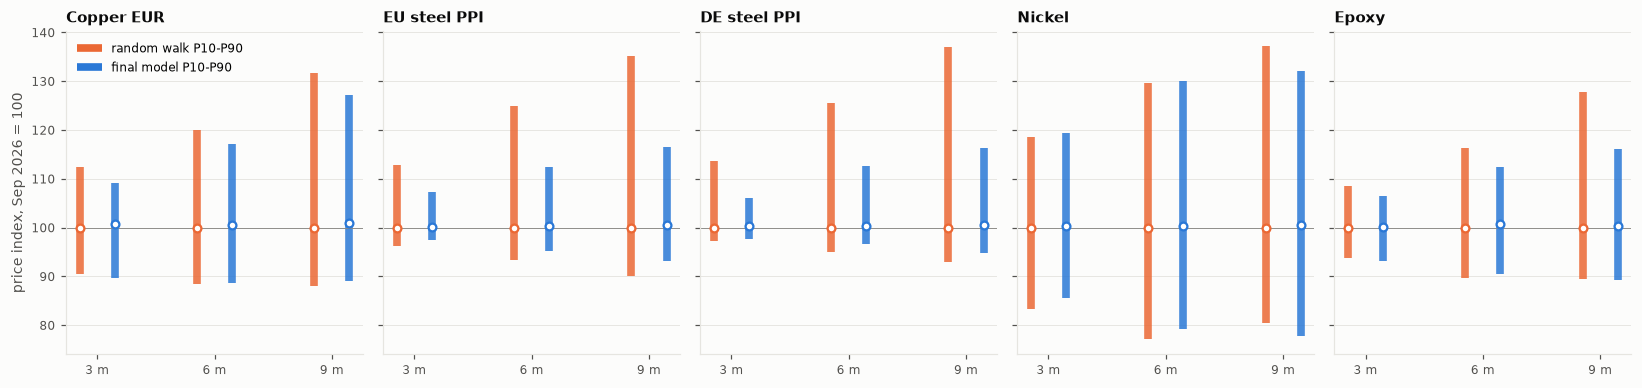

In [18]:
fin = preds[(preds.model == M.FINAL_MODEL) & (preds.origin == preds.origin.max())].copy()
rw = preds[(preds.model == "random_walk") & (preds.origin == preds.origin.max())].copy()
live = pd.concat([fin.assign(model="final"), rw])
for q in ["p10", "p50", "p90", "p95"]:
    live[f"index_{q}"] = 100 * np.exp(live[q])
show = live[live.model == "final"].pivot_table(index="target", columns="horizon", values=["index_p10", "index_p50", "index_p90"])
display(show.rename(index=FP.TARGET_NAMES).round(1))
MP.live_fan(live, ["D01", "S09", "S10", "S03", "EPOXY_EUR"]);

## 9. Findings

1. **No model reliably beats the random walk on the median.** On the hold-out, the final model is +2.5 % / −0.5 % / +0.8 % (pinball skill at 3 / 6 / 9 months), and every confidence interval includes 0. It matches the naive baseline at every horizon, slightly ahead at 3 and 9 months. This is the expected result for monthly commodity prices, and Steps 3–5 predicted it.
2. **The value is in the band.** On the hold-out the final model covers **80–84 %** (target 80 %) with bands **20–33 % narrower** than the random walk's for price indices and epoxy, which over-covered (89–96 %). For pricing: **a smaller buffer with the right protection**.
3. **Momentum in the price indices is real but short.** Every method finds it (Step 4 features, ETS/ARIMA trends, the pooled coefficients), and it pays at 3 months (final model +9 % on PPIs at 3 months on the hold-out; `features_scaled` +16 %). Extrapolated to 6–9 months it hurts.
4. **The backtest was optimistic, by about 6 points.** Mean skill fell from +8.5 % (backtest) to +2.7 % (hold-out) for the final model, and every chosen model shrank. This is why the hold-out was frozen and opened once.
5. **The upside tail is the weak spot: copper.** At 9 months the copper series ended above P90 in 35–41 % of hold-out cases (target 10 %), during the 2025–26 rally. For RM6, which is mainly copper risk, a P90 buffer alone would have been too small: Step 9 should pair the buffer with a **copper indexation clause** for long quotes.
6. **What worked less well.** GARCH falls back to EWMA for the steel and plastics PPIs (non-stationary fit). The pooled model did not help. Classical models over-extrapolate trends and their Gaussian intervals are too narrow. Chronos lost on the backtest but was the best model at 3 months on the hold-out (+6 %, interval excludes 0), and it collapses at 9 months. The LME 3-month forward also did well at 3 months during the copper rally (+8 %). These are **observations made on the hold-out**: switching to them now would be a hold-out-based choice and is not done.

## 10. Limits

- **Small samples:** 38 backtest and 18 hold-out origins per cell, overlapping: about 6 / 3 / 2 independent hold-out windows at 3 / 6 / 9 months. Most differences are within noise.
- **Choices made with hindsight on the backtest** (λ, γ, members): the backtest scores are optimistic; the hold-out is the clean estimate.
- **The hold-out is one regime** (a copper rally, calm steel). The 6- and 9-month hold-out windows partly overlap the selection period (target months after March 2025, origins from mid-2024); the strict hold-out removes that but has 1–2 independent windows.
- **Revised data:** PPIs are today's values, not first releases (Step 1).
- **Chronos** may have seen pre-2025 prices in pretraining; only its hold-out score is clean.

## 11. For the next steps

- **Step 7:** the "beats naive" table and the confidence intervals are in `report/problem1/step6_tables/holdout_beats_naive.csv`; add MASE/WAPE and sub-period results.
- **Step 8:** inputs in `Data/processed/models/step8/` (`--stage export`): live marginals of the final model, standardised monthly residuals and joint H-month scenarios for the dependence between materials.
- **Step 9:** use the P90 / P95 of the final model for the buffer, but **not alone for copper at 6–9 months** (finding 5).
- **Submission CSV:** the final model's live rows (origin September 2026) are already fitted on all data up to the origin.